# Bootstrapping the diffusion-counterfactual results

Two questions, two sections, one bootstrap machine shared with `bootstrapping.ipynb`.

**Every comparison is at one K, `FINAL["k"]` (K=1, the `high` level).** As in the KNN arm,
the model is built on the Aim 1 line plots of `C2_evaluation_diffusion.ipynb` -- every config
at K = 1, 3 -- and that is the only place K is compared. K=1 wins there for both final models
on every disease, so the final system is `I+C+D` and `dual_sal` at K=1, fixed in advance.

**Internal** — within the diffusion arm, exactly the comparisons the KNN notebook makes, with
the same names, Holm families and export: does a counterfactual add anything over the input
alone (`I -> I+C -> I+C+D`, and `xi -> dual -> dual_sal` on the image side), does the
ensemble beat its components, does anything beat MSP.

**External** — diffusion against retrieval, on the **same 20,000 rows and the same folds**.
Both arms are trained on the identical `(split, path)` index, so an arm is just another
score column: the patient bootstrap draws once and both arms are scored on that draw, which
makes every `diffusion - KNN` delta **paired**. That is a far tighter interval than
comparing two independently-bootstrapped CIs, and it is the correct test for this design.

The KNN arm here is `knn_correct_cf_sub20k`, **not** the full-table arm. Same rows, same
folds, so the only thing that differs is where the counterfactual came from. The cost of
that fairness is a smaller retrieval pool (~13k rows in a train partition instead of ~68k),
which is a limitation of the comparison and is stated as one.

## 0. Setup

In [ ]:
import os, json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

sys.path.insert(0, os.path.abspath("code"))
from c2_msp import msp_score
import importlib, thesis_style
importlib.reload(thesis_style)
from thesis_style import *
apply()

RESULTS = os.environ.get("THESIS_RESULTS", "/work3/s251710/thesis_results")
C2      = os.path.join(RESULTS, "C2_final_results")

# The two arms, on the SAME 20k subset. Changing either name changes nothing else.
ARMS    = {"diffusion": "diffusion_hml_sub20k", "KNN": "knn_correct_cf_sub20k"}
MODEL   = "MLP"
POLICY  = "ignore"
MSP_VARIANT = "threshold"        # must match C2_evaluation*.ipynb

# The final system, as FINAL in bootstrapping.ipynb: each family's ablation winner at one K.
# K=1 (the `high` level) beats K=3 for both models on every disease in the Aim 1 line plots;
# K is compared only there. No probability models exist for this arm, so "prob" is False.
FINAL = {"k": 1, "attr": "I+C+D", "cnn": "dual_sal", "prob": False}
N_BOOT, SEED = 5000, 0

ATTR_CONFIGS = ["I", "C", "D", "I+C", "I+C+D"]
CONFIGS      = ATTR_CONFIGS
CF_CONFIGS   = [c for c in ATTR_CONFIGS if c != "I"]
FAMILIES     = {"I": ["I"], "I+C": ["I+C"], "I+C+D": ["I+C+D"]}

CNN_KEYS       = ["xi", "xi_sal", "cf", "cf_sal", "dual", "dual_sal", "dual_sal_scalars"]
CNN_INPUT_KEYS = ["xi", "xi_sal"]
CNN_ONLY_KEYS  = ["cf", "cf_sal"]
CNN_BOTH_KEYS  = ["dual", "dual_sal", "dual_sal_scalars"]
CNN_CF_KEYS    = CNN_ONLY_KEYS + CNN_BOTH_KEYS
ENS_METHODS    = ["mean", "rank", "lr"]
# The image-side ladder, rung for rung with FAMILIES, as in bootstrapping.ipynb.
CNN_FAMILIES   = {"xi": ["xi"], "dual": ["dual"], "dual_sal": ["dual_sal"]}

ARM_COLOR  = {"diffusion": FAMILY["traj"], "KNN": FAMILY["attr"]}
ARM_MARKER = {"diffusion": "o", "KNN": "s"}

## 1. Loaders

Same as `bootstrapping.ipynb`, with `arm` threaded through so one function serves both. A cell that has not finished training returns `None` instead of raising, so this notebook runs mid-campaign.

In [ ]:
def _dir(disease, arm, k, *rest):
    return os.path.join(C2, disease, ARMS[arm], f"cf_{k}", *rest)


def load_attributes(disease, arm, k, n_folds=5):
    """Pooled out-of-fold attribute predictions, or None if the cell is not finished."""
    parts = []
    for i in range(n_folds):
        p = _dir(disease, arm, k, "attributes", f"fold_{i}_predictions.csv")
        if not os.path.exists(p):
            return None
        parts.append(pd.read_csv(p).assign(fold=i))
    return pd.concat(parts, ignore_index=True)


def load_cnn(disease, arm, k, key, n_folds=5):
    if not os.path.exists(_dir(disease, arm, k, "images", key, "fold_aucs.csv")):
        return None
    parts = []
    for i in range(n_folds):
        p = _dir(disease, arm, k, "images", key, f"fold_{i}_predictions.csv")
        if not os.path.exists(p):
            return None
        parts.append(pd.read_csv(p))
    return pd.concat(parts, ignore_index=True).set_index("path")[f"{key}_prob"]


def load_ensemble(disease, arm, k):
    """OOF predictions of c2_ensemble.py, or None if not run. The ensemble must combine the
    final system's two models, or its stars would describe a different ensemble."""
    p = _dir(disease, arm, k, "ensemble", "oof_predictions.csv")
    if not os.path.exists(p):
        return None
    cfg = json.load(open(_dir(disease, arm, k, "ensemble", "run_config.json")))
    assert (cfg["attr_model"], cfg["cnn_model"]) == (f"{MODEL}_{FINAL['attr']}", FINAL["cnn"]), \
        f"{disease}/{arm}/K={k}: ensemble combines {cfg['attr_model']} + {cfg['cnn_model']}, FINAL says {FINAL}"
    return pd.read_csv(p).set_index("path")


def c0_threshold(disease, policy=POLICY):
    p = os.path.join(RESULTS, "C0_final", f"multilabel_{policy}", disease, "threshold.txt")
    return float(open(p).read().strip())


def per_fold_auc(df, col):
    return float(np.mean([roc_auc_score(g["correct"], g[col]) for _, g in df.groupby("fold")]))


def attr_col(c, k, arm=""):  return f"{arm+' ' if arm else ''}{c}@K{k}"
def cnn_col(key, k, arm=""): return f"{arm+' ' if arm else ''}CNN {key}@K{k}"
def ens_col(m, k, arm=""):   return f"{arm+' ' if arm else ''}ENS {m}@K{k}"


def available(disease, arm, k):
    """True when this (disease, arm, K) has attributes, all 7 CNNs and an ensemble."""
    return (load_attributes(disease, arm, k) is not None
            and all(load_cnn(disease, arm, k, key) is not None for key in CNN_KEYS)
            and load_ensemble(disease, arm, k) is not None)


DISEASES_ALL = ["atelectasis", "cardiomegaly", "consolidation", "edema", "effusion"]
# Only diseases whose BOTH arms are finished at the final K can be compared; the internal
# section needs only the diffusion arm.
DISEASES_INT = [d for d in DISEASES_ALL if available(d, "diffusion", FINAL["k"])]
DISEASES_EXT = [d for d in DISEASES_INT if available(d, "KNN", FINAL["k"])]

print("internal (diffusion ready):", ", ".join(DISEASES_INT) or "none")
print("external (both arms ready):", ", ".join(DISEASES_EXT) or "none")

internal (diffusion ready): atelectasis, cardiomegaly, consolidation, edema, effusion
external (both arms ready): atelectasis, cardiomegaly, consolidation, edema, effusion
K available per disease   : {'atelectasis': [1, 3], 'cardiomegaly': [1, 3], 'consolidation': [1, 3], 'edema': [1, 3], 'effusion': [1, 3]}


## 2. The bootstrap

Lifted unchanged from `bootstrapping.ipynb` so both notebooks report the same statistic: **mean-fold AUROC**, resampled by **patient**.

In [ ]:
class WeightedAUC:
    """Weighted AUROC of every score column, for one bootstrap draw.

    AUROC is the share of (correct, incorrect) pairs a score orders correctly. Read a column
    in ascending order and that share is a running total: each correct row contributes the
    incorrect weight below it. The sort is the expensive part and the scores never change,
    so it happens once here and each call is a gather plus a cumulative sum."""
    def __init__(self, table, cols):
        self.cols  = list(cols)
        self.order = np.argsort(table[self.cols].to_numpy(), axis=0, kind="mergesort")
        self.yes   = np.asarray(table["correct"], bool)[self.order]

    def __call__(self, w):
        W     = w[self.order]
        pos   = W * self.yes
        neg   = W * ~self.yes
        below = np.cumsum(neg, axis=0) - neg
        return (pos * below).sum(0) / (pos.sum(0) * neg.sum(0))


class FoldMeanAUC:
    """Mean-fold AUROC: one WeightedAUC per fold, averaged -- the statistic the evaluation
    notebooks report, so the intervals sit on their numbers."""
    def __init__(self, table, cols):
        self.cols  = list(cols)
        fold       = table["fold"].to_numpy()
        self.rows  = [np.flatnonzero(fold == f) for f in np.unique(fold)]
        self.parts = [WeightedAUC(table.iloc[r], self.cols) for r in self.rows]

    def __call__(self, w):
        return np.mean([s(w[r]) for s, r in zip(self.parts, self.rows)], axis=0)


META = ("correct", "patient_id", "fold")


def cmp_bootstrap(tables, n_boot=N_BOOT, seed=SEED):
    """Paired patient-level bootstrap -> DataFrame (replicate x (disease, model))."""
    rng      = np.random.default_rng(seed)
    patients = pd.Index(sorted(set().union(*(set(t.patient_id) for t in tables.values()))))
    codes    = {d: patients.get_indexer(t.patient_id) for d, t in tables.items()}
    scorers  = {d: FoldMeanAUC(t, [c for c in t.columns if c not in META])
                for d, t in tables.items()}
    reps = []
    for b in range(n_boot):
        counts = np.bincount(rng.integers(0, len(patients), len(patients)),
                             minlength=len(patients)).astype(float)
        row = {}
        for d, s in scorers.items():
            vals = s(counts[codes[d]])
            row.update({(d, c): v for c, v in zip(s.cols, vals)})
        reps.append(row)
    out = pd.DataFrame(reps)
    out.columns = pd.MultiIndex.from_tuples(out.columns, names=["disease", "model"])
    out.index.name = "replicate"
    return out


def summarise(x):
    x = np.asarray(x, float)
    lo, hi = np.percentile(x, [2.5, 97.5])
    # Two-sided bootstrap p: how often the replicate sits on the other side of zero.
    p = 2 * min((x <= 0).mean(), (x >= 0).mean())
    # Floored at 1/N_BOOT, as in bootstrapping.ipynb: a tail with no replicates in it is
    # below the bootstrap's resolution, not p = 0.
    return dict(delta=float(x.mean()), lo=float(lo), hi=float(hi),
                p=float(min(1.0, max(p, 1.0 / len(x)))))


def holm(p):
    """Holm-Bonferroni adjusted p-values, order preserved."""
    p = np.asarray(p, float)
    idx = np.argsort(p)
    adj = np.empty_like(p)
    run = 0.0
    for rank, i in enumerate(idx):
        run = max(run, (len(p) - rank) * p[i])
        adj[i] = min(run, 1.0)
    return adj

## 3. Internal — within the diffusion arm

The same comparisons as section 1 of `bootstrapping.ipynb`, all at `FINAL["k"]`:

| group | comparisons |
|---|---|
| `claims` | `I+C - I`, `I+C+D - I+C`, `I+C+D - I`, `CNN dual - xi`, `CNN dual_sal - dual`, `CNN dual_sal - xi`, `best attr - best CNN`, `ensemble - best single`, `best overall - MSP` |
| `msp_plain` | `best overall - plain MSP` -- claim 9 against plain `max(p, 1-p)`, for figure 2a's left panel; an `AVERAGE` row and the claims' two-level Holm |
| `2b` | `ENS <m> - better component`, for `mean`, `rank`, `lr` |

"best attr" and "best CNN" are the fixed `FINAL` models, not a search; only the ensemble's
combiner is chosen, by mean fold AUROC. Holm as in `bootstrapping.ipynb`: a claim's per-disease
rows across the diseases, the claims' `AVERAGE` rows across the claims, and each figure group
across its own rows.

Every model scores the same rows, so one table per disease holds every candidate and the
comparisons are pairs of column lists. A comparison over several columns (a "family
average") averages the AUROC of its members inside each replicate, so the interval is on
the family mean rather than on a winner picked after the fact.

In [ ]:
def build_table(disease, arm, k):
    """One row per C2 sample, one column per candidate score at K=k, plus MSP and the meta cols."""
    ref  = load_attributes(disease, arm, k).set_index("path")
    tab  = ref[["correct", "patient_id", "fold"]].copy()
    aucs = {}

    def add(name, series):
        s = series.reindex(ref.index)
        tab[name] = s.values
        aucs[name] = per_fold_auc(tab.assign(_s=s.values), "_s")

    for c in CONFIGS:
        col = f"{MODEL}_{c}_prob"
        if col in ref.columns:
            add(attr_col(c, k), ref[col])
    for key in CNN_KEYS:
        s = load_cnn(disease, arm, k, key)
        if s is not None:
            add(cnn_col(key, k), s)
    ens = load_ensemble(disease, arm, k)
    if ens is not None:
        for m in [c for c in ens.columns if c.startswith("ens_")]:
            add(ens_col(m[len("ens_"):], k), ens[m])
    add("MSP", pd.Series(msp_score(ref[f"{disease}_prob"].values, c0_threshold(disease),
                                   MSP_VARIANT), index=ref.index))
    # Plain max(p, 1-p), for figure 2a's left panel. Untrained, like MSP.
    add("MSP plain", pd.Series(msp_score(ref[f"{disease}_prob"].values, None, "standard"),
                               index=ref.index))
    return tab, aucs


def picks_internal(disease, aucs, k):
    """Column names for each role the comparisons need, as in bootstrapping.ipynb. Every model
    is fixed by FINAL; only the ensemble's combiner is chosen, by mean fold AUROC."""
    best = lambda names: max(names, key=aucs.get)
    p = {fam: [attr_col(c, k) for c in cs] for fam, cs in FAMILIES.items()}
    p.update({f"cnn_{fam}": [cnn_col(x, k) for x in keys] for fam, keys in CNN_FAMILIES.items()})
    p["best_attr"] = attr_col(FINAL["attr"], k)
    p["best_cnn"]  = cnn_col(FINAL["cnn"], k)
    p["best_ens"]  = best([n for n in aucs if n.startswith("ENS ")])
    p["best_comp"] = best([p["best_attr"], p["best_cnn"]])
    p["best_all"]  = best([p["best_attr"], p["best_cnn"], p["best_ens"]])
    # Figure 2b: the final ensemble's members are the final models (checked in load_ensemble).
    p["ens_k"] = k
    p["ens_attr"], p["ens_cnn"], p["ens_best_comp"] = p["best_attr"], p["best_cnn"], p["best_comp"]
    for m in ENS_METHODS:
        p[f"ens_{m}"] = ens_col(m, k)
    missing = [c for v in p.values() for c in ([v] if isinstance(v, str) else v if isinstance(v, list) else [])
               if c not in aucs]
    assert not missing, f"{disease}: not scored -- {missing}"
    return p


def specs_internal(p, k):
    """(name, high_cols, low_cols, group) -- the same comparisons, names and Holm groups as
    cmp_specs in bootstrapping.ipynb, minus the probability ones (no prob models here)."""
    return [
        ("I+C - I",                 p["I+C"],          p["I"],           "claims"),
        ("I+C+D - I+C",             p["I+C+D"],        p["I+C"],         "claims"),
        ("I+C+D - I",               p["I+C+D"],        p["I"],           "claims"),
        ("CNN dual - xi",           p["cnn_dual"],     p["cnn_xi"],      "claims"),
        ("CNN dual_sal - dual",     p["cnn_dual_sal"], p["cnn_dual"],    "claims"),
        ("CNN dual_sal - xi",       p["cnn_dual_sal"], p["cnn_xi"],      "claims"),
        ("best attr - best CNN",    [p["best_attr"]],  [p["best_cnn"]],  "claims"),
        ("ensemble - best single",  [p["best_ens"]],   [p["best_comp"]], "claims"),
        ("best overall - MSP",      [p["best_all"]],   ["MSP"],          "claims"),
        # Figure 2a's left panel: the same model against the textbook baseline.
        ("best overall - plain MSP", [p["best_all"]],  ["MSP plain"],    "msp_plain"),
    ] + [(f"ENS {m} - better component", [p[f"ens_{m}"]], [p["ens_best_comp"]], "2b")
         for m in ENS_METHODS]


In [ ]:
AVG_GROUPS = ("claims", "msp_plain")   # groups with an AVERAGE row and the two-level Holm, as in the KNN nb


def run_block(diseases, table_fn, picks_fn, specs_fn, knn_holm=False):
    """Bootstrap one block of comparisons -> (deltas, replicates, specs, picks).

    knn_holm=True is the convention of bootstrapping.ipynb, which the internal block uses so
    its stars mean the same as the KNN arm's: an AVERAGE row per claim (the per-disease deltas
    averaged inside each replicate), the claims' AVERAGE rows Holm-adjusted across the claims,
    a claim's per-disease rows across the diseases, and every figure group across its own rows.
    Otherwise Holm runs within each (disease, group), the external block's convention.
    """
    tables, specs, picks = {}, {}, {}
    for d in diseases:
        tab, aucs, sp = table_fn(d)
        tables[d] = tab
        picks[d]  = picks_fn(d, aucs, sp)
        specs[d]  = specs_fn(picks[d], sp)
    boot = cmp_bootstrap(tables)

    rows, per = [], {}
    for d in diseases:
        for name, hi, lo, grp in specs[d]:
            x = (boot[d][hi].mean(axis=1) - boot[d][lo].mean(axis=1)).values
            per.setdefault((name, grp), []).append(x)
            rows.append(dict(disease=d, comparison=name, group=grp, **summarise(x)))
    if knn_holm:
        rows += [dict(disease="AVERAGE", comparison=name, group=grp, **summarise(np.mean(xs, axis=0)))
                 for (name, grp), xs in per.items() if grp in AVG_GROUPS and len(xs) == len(diseases)]
    out = pd.DataFrame(rows)
    out["p_adj"] = np.nan
    if knn_holm:
        avg    = out.disease == "AVERAGE"
        claims = out.group.isin(AVG_GROUPS)
        for _, g in out[avg].groupby("group"):
            out.loc[g.index, "p_adj"] = holm(g.p.values)        # one group's averages
        for _, g in out[claims & ~avg].groupby("comparison"):
            out.loc[g.index, "p_adj"] = holm(g.p.values)        # a claim's diseases
        for _, g in out[~claims].groupby("group"):
            out.loc[g.index, "p_adj"] = holm(g.p.values)        # one figure's rows
    else:
        for _, g in out.groupby(["disease", "group"]):
            out.loc[g.index, "p_adj"] = holm(g.p.values)
    out["sig"] = np.where(out.p_adj < 0.001, "***",
                 np.where(out.p_adj < 0.01, "**",
                 np.where(out.p_adj < 0.05, "*", "")))
    return out, boot, specs, picks


if DISEASES_INT:
    INT_DELTAS, INT_BOOT, INT_SPECS, INT_PICKS = run_block(
        DISEASES_INT,
        lambda d: (*build_table(d, "diffusion", FINAL["k"]), FINAL["k"]),
        picks_internal,
        specs_internal,
        knn_holm=True)
    print(f"{len(INT_DELTAS)} internal comparison rows at K={FINAL['k']}, {N_BOOT} replicates")
    display(INT_DELTAS[["disease", "comparison", "group", "delta", "lo", "hi", "p_adj", "sig"]]
            .round(4))
else:
    INT_DELTAS = None
    print("no disease has a finished diffusion arm yet")


70 internal comparisons, 5000 replicates
          disease                     comparison   delta      lo      hi   p_adj  sig
0     atelectasis                        I+C - I  0.0198  0.0164  0.0231  0.0000  ***
1     atelectasis                    I+C+D - I+C -0.0015 -0.0032  0.0004  0.2248     
2     atelectasis                      I+C+D - I  0.0183  0.0148  0.0218  0.0000  ***
3     atelectasis    CNN CF - input (family avg)  0.0457  0.0414  0.0501  0.0000  ***
4     atelectasis  CNN both - input (family avg)  0.0567  0.0525  0.0607  0.0000  ***
5     atelectasis     CNN both - CF (family avg)  0.0110  0.0085  0.0135  0.0000  ***
6     atelectasis           attr K=3 - K=1 (avg) -0.0098 -0.0110 -0.0087  0.0000  ***
7     atelectasis            CNN K=3 - K=1 (avg) -0.0091 -0.0108 -0.0074  0.0000  ***
8     atelectasis           best attr - best CNN -0.0012 -0.0043  0.0019  0.4360     
9     atelectasis         ensemble - best single  0.0035  0.0019  0.0051  0.0000  ***
10    atelect

## 4. External — diffusion vs retrieval, same rows

At `FINAL["k"]` = 1 on both arms: one counterfactual each, the `high` diffusion edit against
the single nearest retrieved neighbour.

Both arms go into **one table** per disease. The bootstrap draws patients once and scores
both arms on that draw, so `diffusion - KNN` is a paired difference within every replicate.

Three comparisons per disease:

* **matched config** — `I+C` diffusion vs `I+C` KNN, and so on. The cleanest contrast: same
  model, same features, only the counterfactual source differs.
* **best attribute / best CNN / best ensemble** — each arm's own winner, which is what the
  evaluation figures show.
* **family averages** — all CF-dependent attribute configs, and all CF-using CNNs, averaged
  inside each replicate. These do not depend on a winner chosen after seeing the data.

In [ ]:
def build_table_both(disease, k=1):
    """One table carrying BOTH arms' scores over the same rows, for a paired bootstrap."""
    ref = load_attributes(disease, "diffusion", k).set_index("path")
    tab = ref[["correct", "patient_id", "fold"]].copy()
    aucs = {}

    def add(name, series):
        s = series.reindex(ref.index)
        tab[name] = s.values
        aucs[name] = per_fold_auc(tab.assign(_s=s.values), "_s")

    for arm in ARMS:
        a = load_attributes(disease, arm, k).set_index("path")
        # The guard the whole section rests on: identical rows, labels and patients.
        assert len(a) == len(ref) and set(a.index) == set(ref.index), \
            f"{disease}/{arm}: different rows from the diffusion arm"
        al = a.reindex(ref.index)
        assert (al["correct"].values == ref["correct"].values).all(), \
            f"{disease}/{arm}: labels disagree row-for-row"
        for c in CONFIGS:
            col = f"{MODEL}_{c}_prob"
            if col in al.columns:
                add(attr_col(c, k, arm), al[col])
        for key in CNN_KEYS:
            s = load_cnn(disease, arm, k, key)
            if s is not None:
                add(cnn_col(key, k, arm), s)
        ens = load_ensemble(disease, arm, k)
        if ens is not None:
            for m in [c for c in ens.columns if c.startswith("ens_")]:
                add(ens_col(m[len("ens_"):], k, arm), ens[m])
    add("MSP", pd.Series(msp_score(ref[f"{disease}_prob"].values, c0_threshold(disease),
                                   MSP_VARIANT), index=ref.index))
    return tab, aucs


def specs_external(aucs, k=1):
    """Every diffusion-vs-KNN comparison, as (name, diffusion_cols, knn_cols, group)."""
    have = lambda n: n in aucs
    best = lambda names: max([n for n in names if have(n)], key=aucs.get, default=None)
    S = []
    # Matched configs: identical model and features on both sides.
    for c in CONFIGS:
        a, b = attr_col(c, k, "diffusion"), attr_col(c, k, "KNN")
        if have(a) and have(b):
            S.append((f"attr {c}", [a], [b], "matched"))
    for key in CNN_KEYS:
        a, b = cnn_col(key, k, "diffusion"), cnn_col(key, k, "KNN")
        if have(a) and have(b):
            S.append((f"CNN {key}", [a], [b], "matched"))
    # Family averages -- no winner picked after the fact.
    fa = lambda arm: [attr_col(c, k, arm) for c in CF_CONFIGS if have(attr_col(c, k, arm))]
    fc = lambda arm: [cnn_col(x, k, arm) for x in CNN_CF_KEYS if have(cnn_col(x, k, arm))]
    if fa("diffusion") and fa("KNN"):
        S.append(("attr CF-configs (avg)", fa("diffusion"), fa("KNN"), "family"))
    if fc("diffusion") and fc("KNN"):
        S.append(("CNN CF-models (avg)",   fc("diffusion"), fc("KNN"), "family"))
    # Each arm's own winner, which is what the evaluation figures report.
    for label, names in (("best attr", lambda arm: [attr_col(c, k, arm) for c in CONFIGS]),
                         ("best CNN",  lambda arm: [cnn_col(x, k, arm) for x in CNN_KEYS]),
                         ("best ens",  lambda arm: [ens_col(m, k, arm) for m in ENS_METHODS])):
        a, b = best(names("diffusion")), best(names("KNN"))
        if a and b:
            S.append((f"{label} (each arm's own)", [a], [b], "best"))
    return S


if DISEASES_EXT:
    EXT_DELTAS, EXT_BOOT, EXT_SPECS, _ = run_block(
        DISEASES_EXT,
        lambda d: (*build_table_both(d, FINAL["k"]), FINAL["k"]),
        lambda d, a, k: a,
        lambda a, k: specs_external(a, k))
    print(f"{len(EXT_DELTAS)} paired comparisons over {len(DISEASES_EXT)} diseases")
    display(EXT_DELTAS[["disease", "comparison", "group", "delta", "lo", "hi", "p_adj", "sig"]]
            .round(4))
else:
    EXT_DELTAS = None
    print(f"no disease has BOTH arms finished at K={FINAL['k']} yet")

85 paired comparisons over 5 diseases
          disease                  comparison    group   delta      lo      hi   p_adj  sig
0     atelectasis                      attr I  matched  0.0000  0.0000  0.0000  1.0000     
1     atelectasis                      attr C  matched  0.0173  0.0132  0.0216  0.0000  ***
2     atelectasis                      attr D  matched  0.0086  0.0048  0.0125  0.0000  ***
3     atelectasis                    attr I+C  matched  0.0077  0.0046  0.0107  0.0000  ***
4     atelectasis                  attr I+C+D  matched  0.0062  0.0032  0.0092  0.0000  ***
5     atelectasis                      CNN xi  matched -0.0011 -0.0046  0.0022  1.0000     
6     atelectasis                  CNN xi_sal  matched  0.0017 -0.0006  0.0041  0.4416     
7     atelectasis                      CNN cf  matched  0.0282  0.0234  0.0330  0.0000  ***
8     atelectasis                  CNN cf_sal  matched  0.0193  0.0150  0.0236  0.0000  ***
9     atelectasis                    CNN d

## 5. Forest plots

Same layout as `bootstrapping.ipynb`: **one small panel per comparison**, with the diseases
stacked inside it as points and one shared x scale across the whole grid, so bar lengths are
comparable between comparisons rather than only within one.

The bottom row of each panel is **AVERAGE** — the per-replicate delta averaged over diseases,
so it is a bootstrap of the mean effect, not a mean of five separate estimates.

A **filled** dot survives Holm; a **hollow** one does not. Direction needs no encoding: it is
the side of zero.

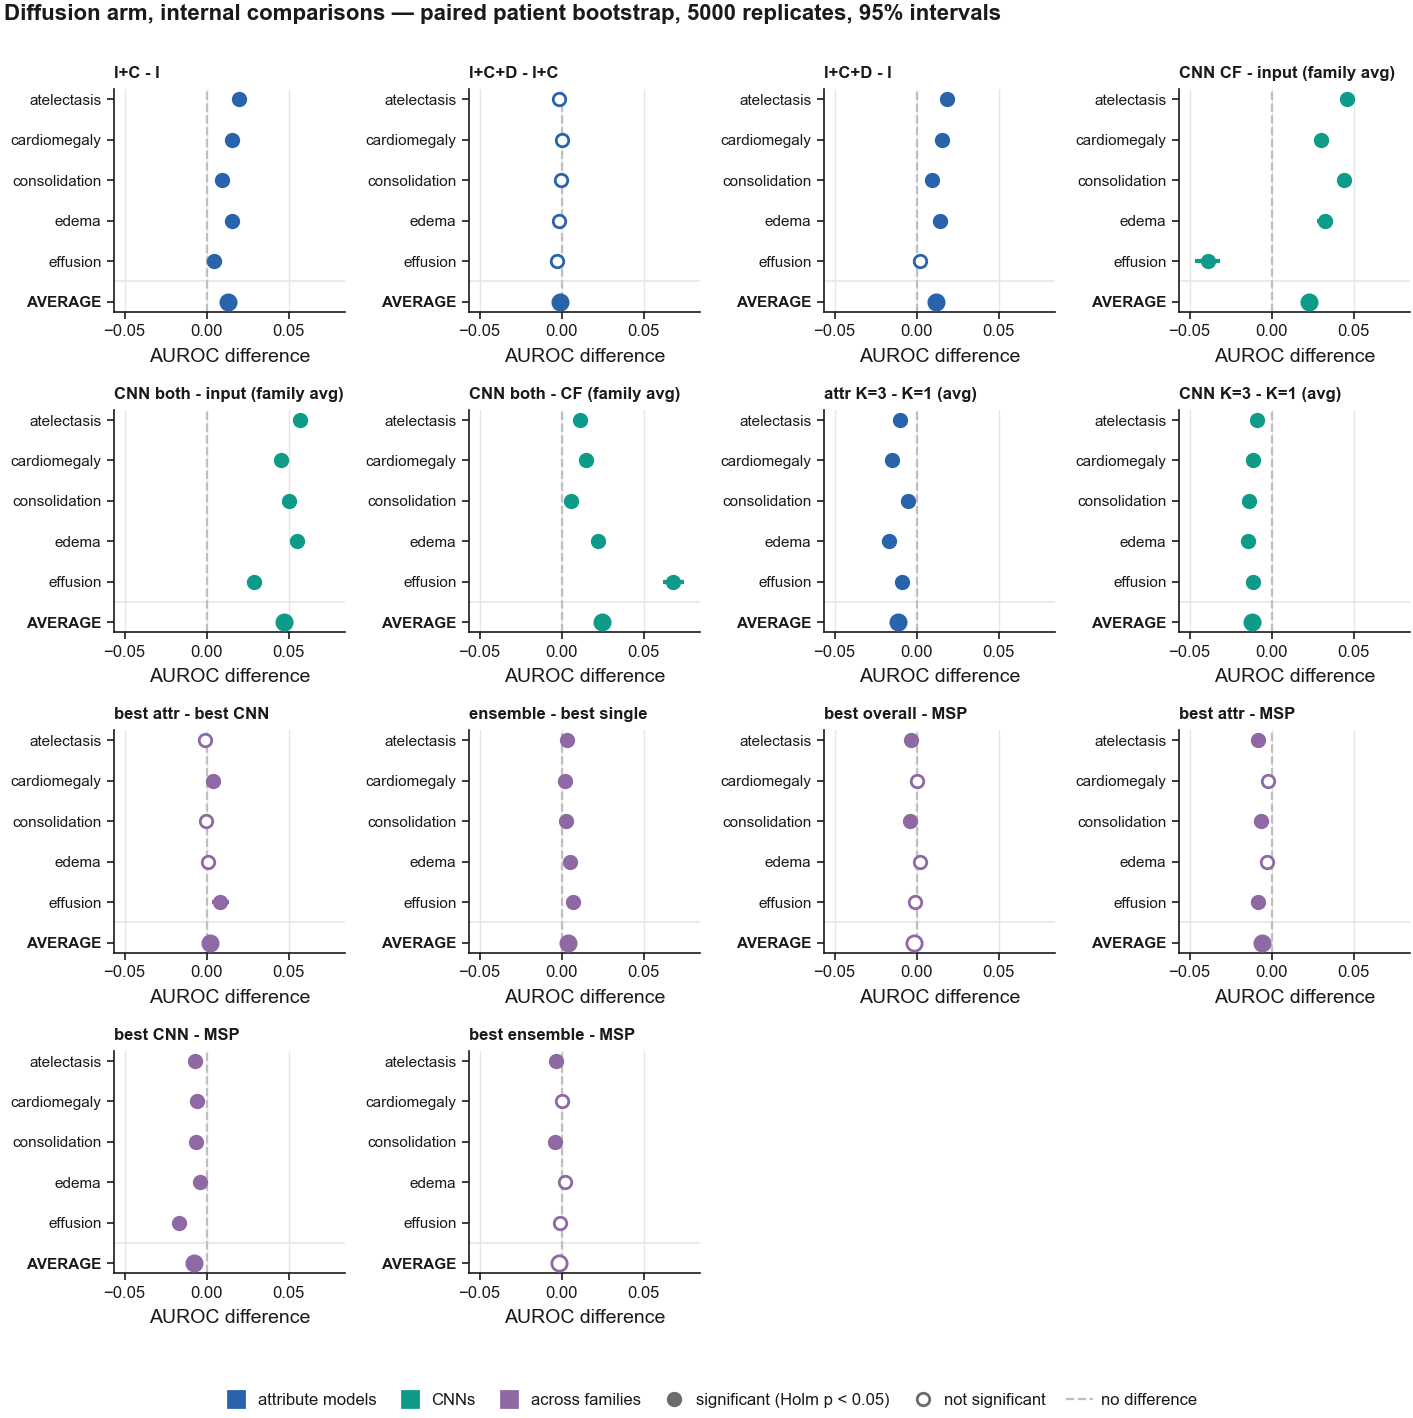

In [ ]:
import textwrap
from matplotlib.lines import Line2D

ALPHA = 0.05


def add_average(deltas, boot, specs_by_disease):
    """Append an AVERAGE row per comparison: the delta averaged ACROSS diseases inside each
    replicate, then summarised. That is a bootstrap of the mean effect -- averaging the five
    per-disease point estimates instead would throw away the pairing between them."""
    ds = list(dict.fromkeys(deltas.disease))
    rows = []
    for name in dict.fromkeys(deltas.comparison):
        per, grp = [], None
        for d in ds:
            sp = {n: (hi, lo, g) for n, hi, lo, g in specs_by_disease[d]}
            if name not in sp:
                continue
            hi, lo, grp = sp[name]
            per.append((boot[d][hi].mean(axis=1) - boot[d][lo].mean(axis=1)).values)
        if len(per) == len(ds):          # only average a comparison every disease carries
            rows.append(dict(disease="AVERAGE", comparison=name, group=grp,
                             **summarise(np.mean(per, axis=0))))
    if not rows:
        return deltas
    avg = pd.DataFrame(rows)
    avg["p_adj"] = holm(avg["p"].values)          # Holm across comparisons, as in the KNN nb
    avg["sig"] = np.where(avg.p_adj < 0.001, "***",
                 np.where(avg.p_adj < 0.01, "**",
                 np.where(avg.p_adj < ALPHA, "*", "")))
    return pd.concat([deltas, avg], ignore_index=True)


def panel_forest(deltas, color_fn, title, ncols=4, panel=(FULL / 4, 44 * MM),
                 names=None, legend=None):
    """One panel per comparison; diseases stacked inside it. Shared x scale across the grid."""
    if deltas is None or deltas.empty:
        print("nothing to plot yet"); return
    names = names or list(dict.fromkeys(deltas.comparison))
    order = [d for d in deltas.disease.unique() if d != "AVERAGE"]
    if "AVERAGE" in set(deltas.disease):
        order = order + ["AVERAGE"]
    nrows = int(np.ceil(len(names) / ncols))
    shown = deltas[deltas.comparison.isin(names)]
    xmin, xmax = min(shown.lo.min(), 0), max(shown.hi.max(), 0)
    pad = 0.08 * (xmax - xmin) if xmax > xmin else 0.01

    fig, axes = plt.subplots(nrows, ncols, figsize=(panel[0] * ncols, panel[1] * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax, name in zip(axes, names):
        g = deltas[deltas.comparison == name].set_index("disease")
        rows = [d for d in order if d in g.index]
        y = np.arange(len(rows))[::-1]
        ax.axvline(0, color=GREY, ls="--", lw=LW["ref"], zorder=1)
        if "AVERAGE" in rows:
            ax.axhline(0.5, color=HAIR, lw=LW["axis"], zorder=0)   # set AVERAGE apart
        for yi, d in zip(y, rows):
            r = g.loc[d]
            c = color_fn(name, r)
            sig = r.p_adj < ALPHA
            ms = 5.5 if d == "AVERAGE" else 4.5
            ax.plot([r.lo, r.hi], [yi, yi], color=c, lw=LW["line"],
                    solid_capstyle="butt", zorder=2)
            ax.plot(r.delta, yi, "o", ms=ms, mfc=c if sig else "white", mec=c,
                    mew=1.0, zorder=3)
        ax.set_xlim(xmin - pad, xmax + pad)
        ax.grid(axis="x", zorder=0); ax.set_axisbelow(True)
        ax.set_yticks(y, rows, fontsize=FS["tiny"])
        if "AVERAGE" in rows:
            ax.get_yticklabels()[-1].set_fontweight("bold")
        ax.set_title("\n".join(textwrap.wrap(name, 30)), fontsize=FS["small"])
        ax.set_xlabel("AUROC difference")
        ax.tick_params(labelbottom=True)
    for ax in axes[len(names):]:
        ax.axis("off")
    if legend:
        fig.legend(handles=legend, loc="lower center", ncol=min(6, len(legend)),
                   bbox_to_anchor=(0.5, -0.02))
    fig.suptitle(title, x=0.01, ha="left", y=1.0)
    fig.tight_layout(rect=(0, 0.03, 1, 1))
    plt.show()
    return fig


# Internal: colour by the model family the comparison is about, as in bootstrapping.ipynb.
def int_color(name, row):
    if name.startswith("CNN "):  return FAMILY["cnn"]
    if name.startswith(("I", "attr ")): return FAMILY["attr"]
    return ENS


# run_block already added the AVERAGE rows, kNN-style. msp_plain is left out, as in the KNN
# forest: its gains are ~5x the claims' and would flatten the shared x scale.
INT_PLOT = INT_DELTAS[INT_DELTAS.group != "msp_plain"] if INT_DELTAS is not None else None
panel_forest(INT_PLOT, int_color,
             f"Diffusion arm, internal comparisons — paired patient bootstrap, "
             f"{N_BOOT} replicates, 95% intervals",
             legend=[patch_handle(FAMILY["attr"], "attribute models"),
                     patch_handle(FAMILY["cnn"], "CNNs"),
                     patch_handle(ENS, "across families"),
                     Line2D([], [], color=MUTED, lw=0, marker="o", ms=4.5,
                            label=f"significant (Holm p < {ALPHA})"),
                     Line2D([], [], color=MUTED, lw=0, marker="o", ms=4.5, mfc="white",
                            mew=1.0, label="not significant"),
                     Line2D([], [], color=GREY, lw=LW["ref"], ls="--", label="no difference")])

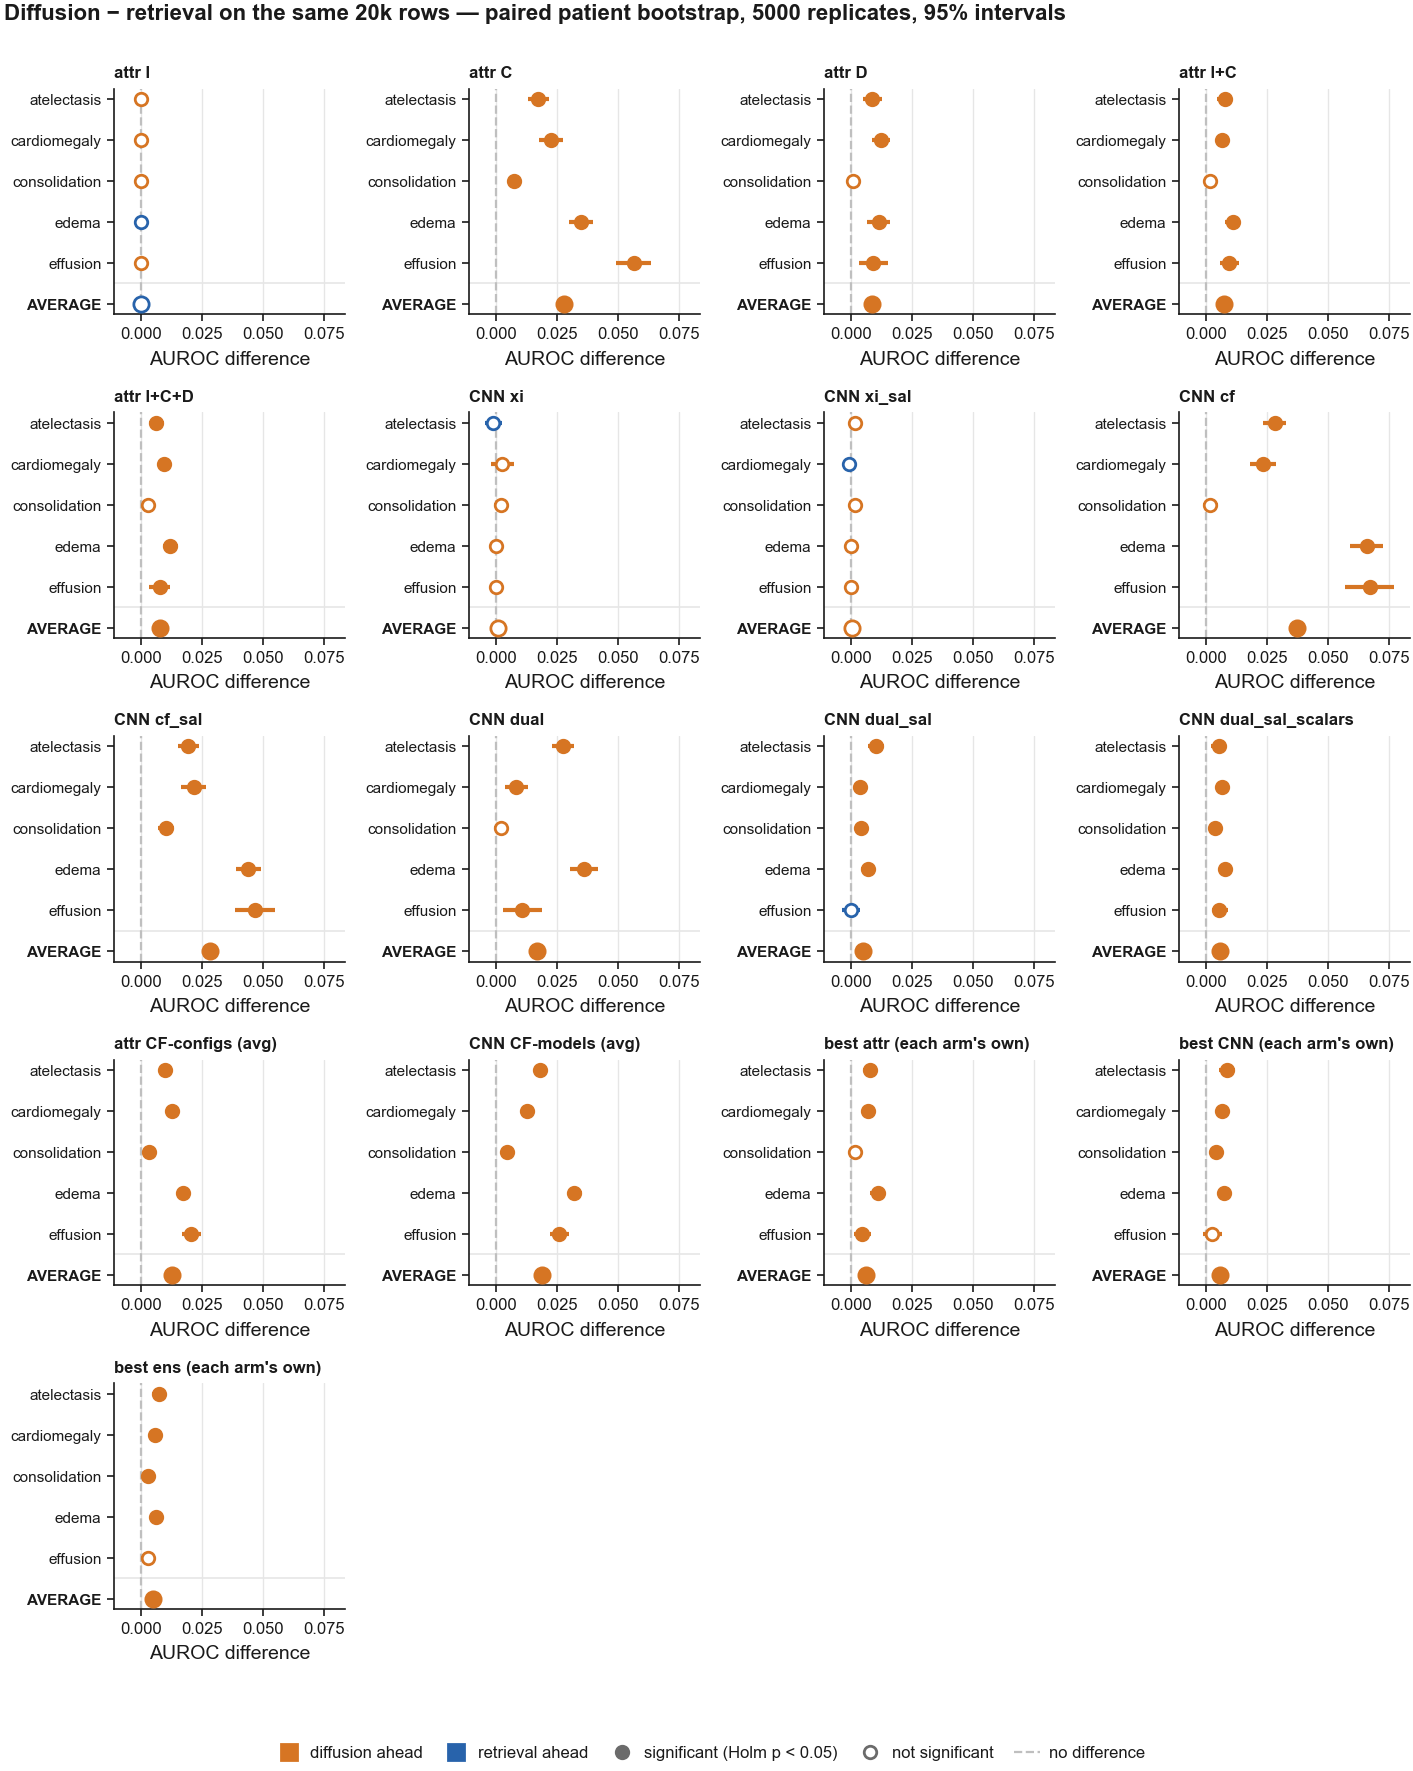

In [ ]:
# External: the sign IS the finding, so colour carries it -- green right of zero means
# diffusion ahead, blue left means retrieval ahead, matching C2_evaluation_diffusion.ipynb.
def ext_color(name, row):
    return ARM_COLOR["diffusion"] if row.delta >= 0 else ARM_COLOR["KNN"]


EXT_PLOT = add_average(EXT_DELTAS, EXT_BOOT, EXT_SPECS) if EXT_DELTAS is not None else None
panel_forest(EXT_PLOT, ext_color,
             f"Diffusion − retrieval on the same 20k rows — paired patient bootstrap, "
             f"{N_BOOT} replicates, 95% intervals",
             legend=[patch_handle(ARM_COLOR["diffusion"], "diffusion ahead"),
                     patch_handle(ARM_COLOR["KNN"], "retrieval ahead"),
                     Line2D([], [], color=MUTED, lw=0, marker="o", ms=4.5,
                            label=f"significant (Holm p < {ALPHA})"),
                     Line2D([], [], color=MUTED, lw=0, marker="o", ms=4.5, mfc="white",
                            mew=1.0, label="not significant"),
                     Line2D([], [], color=GREY, lw=LW["ref"], ls="--", label="no difference")])

## 6. Verdict

The external question stated plainly, so the numbers are not left to the reader to assemble.

In [ ]:
def verdict(deltas, label):
    if deltas is None or deltas.empty:
        print(f"{label}: nothing to report yet"); return
    tot = len(deltas)
    pos = (deltas.delta > 0).sum()
    sig = deltas[deltas.p_adj < 0.05]
    sig_pos = (sig.delta > 0).sum()
    print(f"{label}")
    print(f"  {tot} comparisons over {deltas.disease.nunique()} diseases")
    print(f"  positive delta      : {pos}/{tot}")
    print(f"  significant (Holm)  : {len(sig)}/{tot}  ({sig_pos} positive, "
          f"{len(sig)-sig_pos} negative)")
    if len(sig):
        w = sig.loc[sig.delta.idxmax()]
        print(f"  largest significant : {w.comparison} on {w.disease}  "
              f"{w.delta:+.4f} [{w.lo:+.4f}, {w.hi:+.4f}]")
    print()
    for d, g in deltas.groupby("disease", sort=False):
        s = g[g.p_adj < 0.05]
        print(f"  {d:14s} {len(s):2d}/{len(g):2d} significant, "
              f"median Δ {g.delta.median():+.4f}")


verdict(EXT_DELTAS, "EXTERNAL — diffusion vs retrieval, same 20k rows")
print()
verdict(INT_DELTAS, "INTERNAL — within the diffusion arm")

EXTERNAL — diffusion vs retrieval, same 20k rows
  85 comparisons over 5 diseases
  positive delta      : 73/85
  significant (Holm)  : 61/85  (61 positive, 0 negative)
  largest significant : CNN cf on effusion  +0.0672 [+0.0572, +0.0771]

  atelectasis    14/17 significant, median Δ +0.0086
  cardiomegaly   14/17 significant, median Δ +0.0069
  consolidation   8/17 significant, median Δ +0.0027
  edema          14/17 significant, median Δ +0.0110
  effusion       11/17 significant, median Δ +0.0076

INTERNAL — within the diffusion arm
  70 comparisons over 5 diseases
  positive delta      : 37/70
  significant (Holm)  : 53/70  (30 positive, 23 negative)
  largest significant : CNN both - CF (family avg) on effusion  +0.0679 [+0.0615, +0.0743]

  atelectasis    12/14 significant, median Δ -0.0013
  cardiomegaly   10/14 significant, median Δ +0.0013
  consolidation  12/14 significant, median Δ -0.0003
  edema           9/14 significant, median Δ +0.0021
  effusion       10/14 significa

## 7. Export

Written in the **same shape** `bootstrapping.ipynb` uses, so `C2_evaluation_diffusion.ipynb`
can read it with the KNN notebook's loader and guards unchanged:

    bootstrap_diffusion_replicates.csv   replicate x "disease|model", mean-fold AUROC
    bootstrap_diffusion_deltas.csv       one row per comparison, AVERAGE rows included
    bootstrap_diffusion_meta.json        config + the models the bootstrap picked

`picks` is what `check_bootstrap_picks()` and `check_bootstrap_ensemble()` compare against,
so a star can never be drawn next to a number the bootstrap did not compute. They are the
picks the internal comparisons actually used.

The file names carry `_diffusion_`, so this export and the KNN one can never overwrite
each other.

In [ ]:
import json, datetime

def _flat(boot):
    """MultiIndex (disease, model) -> flat "disease|model" header, as the KNN export does."""
    r = boot.copy()
    r.columns = [f"{d}|{m}" for d, m in r.columns]
    return r


ALPHA = 0.05
meta = {"created": datetime.datetime.now().isoformat(timespec="seconds"),
        "n_boot": N_BOOT, "seed": SEED, "alpha": ALPHA, "model": MODEL,
        "msp_variant": MSP_VARIANT,
        # `diseases` is the internal set: the one the evaluation notebook plots.
        "diseases": DISEASES_INT, "families": FAMILIES, "cnn_families": CNN_FAMILIES,
        "final": FINAL, "picks": INT_PICKS if INT_DELTAS is not None else {},
        # Diffusion-only additions. The KNN loader ignores keys it does not read.
        "arms": ARMS, "diseases_external": DISEASES_EXT}

wrote = []
if INT_DELTAS is not None:
    _flat(INT_BOOT).to_csv(os.path.join(C2, "bootstrap_diffusion_replicates.csv"),
                           index_label="replicate")
    INT_DELTAS.to_csv(os.path.join(C2, "bootstrap_diffusion_deltas.csv"), index=False)
    wrote += [f"replicates.csv  {INT_BOOT.shape[1]} columns x {len(INT_BOOT)} replicates",
              f"deltas.csv      {len(INT_DELTAS)} comparison rows"]
if EXT_DELTAS is not None:
    # The arm comparison has no counterpart in the KNN export, so it keeps its own pair.
    _flat(EXT_BOOT).to_csv(os.path.join(C2, "bootstrap_diffusion_external_replicates.csv"),
                           index_label="replicate")
    # With the AVERAGE rows (add_average, section 5), so the evaluation notebook's arm figure
    # can draw an average panel with its own test instead of re-deriving one.
    ext_out = add_average(EXT_DELTAS, EXT_BOOT, EXT_SPECS)
    ext_out.to_csv(os.path.join(C2, "bootstrap_diffusion_external.csv"), index=False)
    wrote += [f"external.csv    {len(ext_out)} paired diffusion-KNN comparisons (AVERAGE incl.)"]

json.dump(meta, open(os.path.join(C2, "bootstrap_diffusion_meta.json"), "w"), indent=1)
wrote.append("meta.json       picks for " + ", ".join(meta["picks"]))
print("wrote to " + C2 + ":")
for w in wrote:
    print("  " + w)


wrote to /work3/s251710/thesis_results/C2_final_results:
  replicates.csv  155 columns x 5000 replicates
  deltas.csv      70 comparisons
  external.csv    85 paired diffusion-KNN comparisons
  meta.json       picks for atelectasis, cardiomegaly, consolidation, edema, effusion


## 8. E-AURC on the same draws

Figure 2a's second panel: the E-AURC gain of the final system's best model (`best_all`) over the
adjusted MSP, `E-AURC(MSP) - E-AURC(best)`, so positive is better. E-AURC is mean-fold, like
every AUROC here.

It is computed on the **saved** export's draws, not a new bootstrap. The draws depend only on
the seed and the patient set, so replaying `default_rng(seed)` over the same rows reproduces
every replicate's patient weights. The replay also rescores the adjusted MSP's AUROC, and that
must equal the export's `MSP` column exactly before anything is written. That check is what
makes these intervals paired with the main ones.

Holm runs across the diseases; the `AVERAGE` row (averaged inside each replicate) is alone in
its family. The code is in `code/c2_boot_extra.py`. The weighted E-AURC is exact (a patient
drawn w times is w consecutive rows of the ranking), and the cell checks it against the unweighted
definition at unit weights. Output: `bootstrap_diffusion_eaurc_replicates.csv`, `bootstrap_diffusion_eaurc_deltas.csv`.


In [ ]:
import importlib, json
import c2_boot_extra as BX
importlib.reload(BX)

# Everything is read from the saved export, so this extends exactly what is on disk.
_PFX   = os.path.join(C2, "bootstrap_diffusion_")
_meta  = json.load(open(_PFX + "meta.json"))
_main  = pd.read_csv(_PFX + "replicates.csv", index_col="replicate")
E_DISEASES, E_PICKS, E_K = _meta["diseases"], _meta["picks"], _meta["final"]["k"]


def best_score(disease, name):
    """Score of a bootstrap model name ("ENS lr@K10", "CNN dual_sal@K10", "I+C+D@K10"),
    indexed by path."""
    what = name.rsplit("@", 1)[0]
    if what.startswith("ENS "):
        return load_ensemble(disease, "diffusion", E_K)["ens_" + what[4:]]
    if what.startswith("CNN "):
        return load_cnn(disease, "diffusion", E_K, what[4:])
    return load_attributes(disease, "diffusion", E_K).set_index("path")[f"{MODEL}_{what}_prob"]


def eaurc_tables():
    """The main bootstrap's rows (the attribute frame at the final K) with the two scores the
    E-AURC panel needs: the adjusted MSP and the best overall model."""
    tabs = {}
    for d in E_DISEASES:
        ref = load_attributes(d, "diffusion", E_K).set_index("path")
        tab = ref[["correct", "patient_id", "fold"]].copy()
        tab["MSP"] = msp_score(ref[f"{d}_prob"].values, c0_threshold(d), MSP_VARIANT)
        tab[E_PICKS[d]["best_all"]] = best_score(d, E_PICKS[d]["best_all"]).reindex(ref.index).values
        assert tab.notna().all().all(), f"{d}: missing scores"
        tabs[d] = tab.reset_index(drop=True)
    return tabs


E_TABLES = eaurc_tables()
# Exactness: at unit weights the weighted E-AURC is the plain fold-mean E-AURC.
_t, _c = E_TABLES[E_DISEASES[0]], "MSP"
print("unit-weight check:",
      BX.FoldMean(_t, [_c], BX.WeightedEAURC)(np.ones(len(_t)))[0],
      np.mean([BX.e_aurc(g.correct, g[_c]) for _, g in _t.groupby("fold")]))

E_AUC, E_EAURC = BX.extra_bootstrap(E_TABLES, ["MSP"], _meta["n_boot"], _meta["seed"])
for d in E_DISEASES:                                   # the pairing check
    diff = np.abs(E_AUC[d]["MSP"].to_numpy() - _main[f"{d}|MSP"].to_numpy()).max()
    assert diff < 1e-12, f"{d}: replayed draws differ from the export (max |diff| {diff:.1e})"
print("replayed draws match the export on every disease")

E_DELTAS = BX.extra_deltas(E_EAURC, E_PICKS, E_DISEASES)
_r = E_EAURC.copy(); _r.columns = [f"{d}|{m}" for d, m in _r.columns]
_r.to_csv(_PFX + "eaurc_replicates.csv", index_label="replicate")
E_DELTAS.to_csv(_PFX + "eaurc_deltas.csv", index=False)
E_DELTAS.round(4).set_index("disease")


## 9. K = 3 vs K = 1, within each arm

Table 5b of `TABLES.ipynb`: does going from one counterfactual to three help? For KNN, K is the number of nearest
retrieved neighbours; for diffusion, the number of intensity levels pooled (K=1 `high`; K=3 adds `mid` and `low`).
The models are the final ones, at both K: attribute MLP `I+C+D`, CNN `dual_sal`, and their ensemble with **the arm's
best combiner at K=1** (by mean-fold AUROC, as in Section 5 of `TABLES.ipynb`), kept fixed at K=3 so the delta is
only the change in K.

Every comparison is `K=3 - K=1` on the same rows, so it is paired within each replicate. The draws are **replayed**
from the saved external export (same seed, same rows, so the same patient set), and the cell checks that the replayed
`MSP` column equals the export's before anything is written. Only this section and the setup (sections 0 to 2) need
to run; the heavy bootstraps in sections 3 and 4 do not.

Holm: per arm and model, across the five diseases (the convention of Tables 3b and 4). The `AVERAGE` rows (delta
averaged over diseases inside each replicate) are Holm-adjusted across the three models within each arm.
Output: `bootstrap_diffusion_k_replicates.csv`, `bootstrap_diffusion_k_deltas.csv`.

In [ ]:
K_PAIR = (1, 3)
K_FAMS = {"attr": f"{MODEL}_{FINAL['attr']}_prob", "cnn": FINAL["cnn"], "ens": None}
_EXT_META = json.load(open(os.path.join(C2, "bootstrap_diffusion_meta.json")))
K_DISEASES = _EXT_META["diseases_external"]


def k_tables():
    """One table per disease: both arms' final models at both K, on the external export's rows.
    Returns (tables, ensemble combiner per (disease, arm))."""
    k1, k3 = K_PAIR
    tabs, comb = {}, {}
    for d in K_DISEASES:
        ref = load_attributes(d, "diffusion", k1).set_index("path")     # the external export's rows
        tab = ref[["correct", "patient_id", "fold"]].copy()
        tab["MSP"] = msp_score(ref[f"{d}_prob"].values, c0_threshold(d), MSP_VARIANT)
        for arm in ARMS:
            ens = {k: load_ensemble(d, arm, k) for k in K_PAIR}
            # The arm's best combiner at K=1, fixed at K=3.
            m1 = ens[k1].reindex(ref.index).assign(fold=tab["fold"].values)
            comb[(d, arm)] = max(ENS_METHODS, key=lambda m: per_fold_auc(m1, f"ens_{m}"))
            for k in K_PAIR:
                a = load_attributes(d, arm, k).set_index("path")
                assert set(a.index) == set(ref.index), f"{d}/{arm}/K={k}: different rows"
                a = a.reindex(ref.index)
                assert (a["correct"].values == ref["correct"].values).all() and \
                       (a["fold"].values == ref["fold"].values).all(), f"{d}/{arm}/K={k}: labels or folds differ"
                tab[f"{arm} attr@K{k}"] = a[K_FAMS["attr"]].values
                tab[f"{arm} cnn@K{k}"]  = load_cnn(d, arm, k, FINAL["cnn"]).reindex(ref.index).values
                tab[f"{arm} ens@K{k}"]  = ens[k][f"ens_{comb[(d, arm)]}"].reindex(ref.index).values
        assert tab.notna().all().all(), f"{d}: missing scores"
        tabs[d] = tab.reset_index(drop=True)
    return tabs, comb


K_TABLES, K_COMB = k_tables()
K_BOOT = cmp_bootstrap(K_TABLES, _EXT_META["n_boot"], _EXT_META["seed"])

# The pairing check: the replayed MSP must be the external export's MSP, replicate for replicate.
_ext = pd.read_csv(os.path.join(C2, "bootstrap_diffusion_external_replicates.csv"), index_col="replicate",
                   usecols=lambda c: c == "replicate" or c.endswith("|MSP"))
for d in K_DISEASES:
    diff = np.abs(K_BOOT[d]["MSP"].to_numpy() - _ext[f"{d}|MSP"].to_numpy()).max()
    assert diff < 1e-12, f"{d}: replayed draws differ from the export (max |diff| {diff:.1e})"
print("replayed draws match the external export on every disease")

k1, k3 = K_PAIR
rows, per = [], {}
for d in K_DISEASES:
    obs = FoldMeanAUC(K_TABLES[d], [c for c in K_TABLES[d].columns if c not in META])
    obs = dict(zip(obs.cols, obs(np.ones(len(K_TABLES[d])))))      # unit weights = the observed AUROC
    for arm in ARMS:
        for fam in K_FAMS:
            hi, lo = f"{arm} {fam}@K{k3}", f"{arm} {fam}@K{k1}"
            x = (K_BOOT[d][hi] - K_BOOT[d][lo]).values
            per.setdefault((arm, fam), []).append(x)
            rows.append(dict(disease=d, arm=arm, model=fam, comparison=f"{arm} {fam} K{k3} - K{k1}",
                             combiner=K_COMB[(d, arm)] if fam == "ens" else "",
                             observed=obs[hi] - obs[lo], **summarise(x)))
for (arm, fam), xs in per.items():
    x = np.mean(xs, axis=0)
    rows.append(dict(disease="AVERAGE", arm=arm, model=fam, comparison=f"{arm} {fam} K{k3} - K{k1}",
                     combiner="", observed=np.mean([r["observed"] for r in rows
                                                    if r["arm"] == arm and r["model"] == fam]),
                     **summarise(x)))
K_DELTAS = pd.DataFrame(rows)
K_DELTAS["p_adj"] = np.nan
avg = K_DELTAS.disease == "AVERAGE"
for _, g in K_DELTAS[~avg].groupby(["arm", "model"]):
    K_DELTAS.loc[g.index, "p_adj"] = holm(g.p.values)      # one model in one arm, across the diseases
for _, g in K_DELTAS[avg].groupby("arm"):
    K_DELTAS.loc[g.index, "p_adj"] = holm(g.p.values)      # an arm's averages, across the three models
K_DELTAS["sig"] = np.where(K_DELTAS.p_adj < 0.001, "***",
                  np.where(K_DELTAS.p_adj < 0.01, "**",
                  np.where(K_DELTAS.p_adj < 0.05, "*", "")))

_r = K_BOOT.copy(); _r.columns = [f"{d}|{m}" for d, m in _r.columns]
_r.to_csv(os.path.join(C2, "bootstrap_diffusion_k_replicates.csv"), index_label="replicate")
K_DELTAS.to_csv(os.path.join(C2, "bootstrap_diffusion_k_deltas.csv"), index=False)
display(K_DELTAS[["disease", "arm", "model", "combiner", "observed", "lo", "hi", "p_adj", "sig"]].round(4))
